# CelebA Attribute Rebalancing: Design and Properties

Reference notebook for the CelebA confounding design used in the counterfactual face-image
experiments (Dance et al., 2026, Section 5.4 and Appendix B.3). It documents the controlled
observational construction, verifies its statistics against the prescribed design exactly, and
records the overlap and feasibility constraints. No estimator is fitted here.

In [1]:
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.append("../../src")

from causality_utils import effective_sample_size
from data_utils import binary_stats, load_celeba_paper, to_image_range

CACHE = "../../data/celeba_dgp/celeba_paper_64_n20000_seed0.pt"
CELEBA_ROOT = "/nfs/ghome/live/danceh/data/celeba"   # machine-local; used only to (re)generate

## 1. Design

$$
A = \mathrm{Male} \in \{0, 1\}, \qquad
X = \mathrm{HairColor} \in \{0 \text{ (brown)},\, 1 \text{ (blond)}\}, \qquad
Y = 64 \times 64 \text{ RGB face},
$$

with the controlled observational sample drawn **without replacement and disjointly** per $(A, X)$
cell from a cleaned pool (official train + valid splits; exactly one of Blond/Brown hair, dropping
Black/Gray/Bald/Hat), at the prescribed proportions

$$
P(X = 1) = 0.3, \qquad P(A = 1 \mid X = 0) = 0.6, \qquad P(A = 1 \mid X = 1) = 0.1,
$$

with $n_{\mathrm{obs}} = 20{,}000$; balanced references for each interventional law $P(Y(a))$ use
$P_{\mathrm{ref}}(X = 1 \mid \mathrm{do}(A = a)) = 0.3$ with $2{,}000$ images per arm.

**Fidelity to the reference construction.** `data_utils.celeba` reimplements the released
construction with identical cleaning, sampling order, and largest-remainder cell rounding. Verified
against the reference code on this data root: the cleaned pool contains **61,037** records with
identical per-cell counts *and identical file sets*, and the deterministic observed/reference cell
counts at the configuration above match exactly — observed cells
$(A,X)$: $(0,0) \to 5600$, $(1,0) \to 8400$, $(0,1) \to 5400$, $(1,1) \to 600$.

In [2]:
data = load_celeba_paper(CACHE, root=CELEBA_ROOT, seed=0, image_size=64,
                         n_obs=20000, n_ref=2000, verbose=False)
A = data["A"].view(-1).long()
X = data["X"].view(-1).long()
Y = data["Y"]
stats = binary_stats(A, X)
print(f"n = {stats['n']}")
print(f"P(X=1)      = {stats['P(X=1)']:.4f}   (prescribed 0.3)")
print(f"P(A=1|X=0)  = {stats['P(A=1|X=0)']:.4f}   (prescribed 0.6)")
print(f"P(A=1|X=1)  = {stats['P(A=1|X=1)']:.4f}   (prescribed 0.1)")
print(f"cells (A,X) = { {k: v for k, v in sorted(stats['cells'].items())} }")
print(f"references:  P_ref(X=1|do(A=0)) = {data['X0_ref'].mean():.4f}   "
      f"P_ref(X=1|do(A=1)) = {data['X1_ref'].mean():.4f}   (prescribed 0.3)")

n = 20000
P(X=1)      = 0.3000   (prescribed 0.3)
P(A=1|X=0)  = 0.6000   (prescribed 0.6)
P(A=1|X=1)  = 0.1000   (prescribed 0.1)
cells (A,X) = {(0, 0): 5600, (0, 1): 5400, (1, 0): 8400, (1, 1): 600}
references:  P_ref(X=1|do(A=0)) = 0.3000   P_ref(X=1|do(A=1)) = 0.3000   (prescribed 0.3)


## 2. Samples

One row per observed $(A, X)$ cell, then the two balanced interventional references.

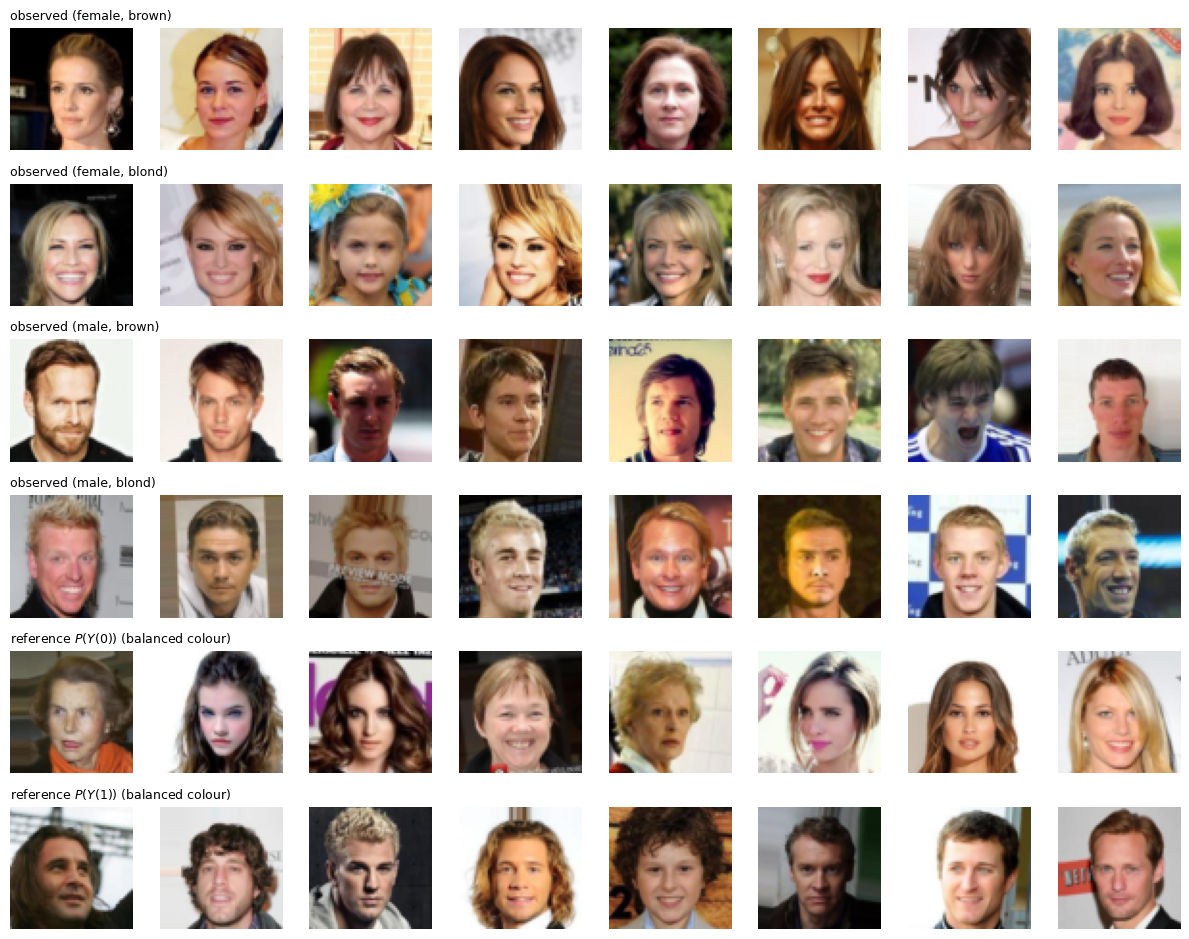

In [3]:
cells = {(0, 0): "female, brown", (0, 1): "female, blond",
         (1, 0): "male, brown", (1, 1): "male, blond"}
fig, axes = plt.subplots(6, 8, figsize=(12, 9.5))
for r, ((a, x), label) in enumerate(cells.items()):
    idx = torch.where((A == a) & (X == x))[0][:8]
    for k, ax in enumerate(axes[r]):
        ax.imshow(to_image_range(Y[idx[k]]).permute(1, 2, 0).cpu().numpy())
        ax.axis("off")
    axes[r, 0].set_title(f"observed ({label})", fontsize=9, loc="left")
for r, arm in enumerate((0, 1)):
    reference = data[f"Y{arm}_ref"]
    for k, ax in enumerate(axes[4 + r]):
        ax.imshow(to_image_range(reference[k]).permute(1, 2, 0).cpu().numpy())
        ax.axis("off")
    axes[4 + r, 0].set_title(f"reference $P(Y({arm}))$ (balanced colour)", fontsize=9, loc="left")
fig.tight_layout()
plt.show()

### Mean face per cell

Cell-mean images summarise what the confounder controls: hair brightness varies with $X$ within
each arm, and facial structure with $A$.

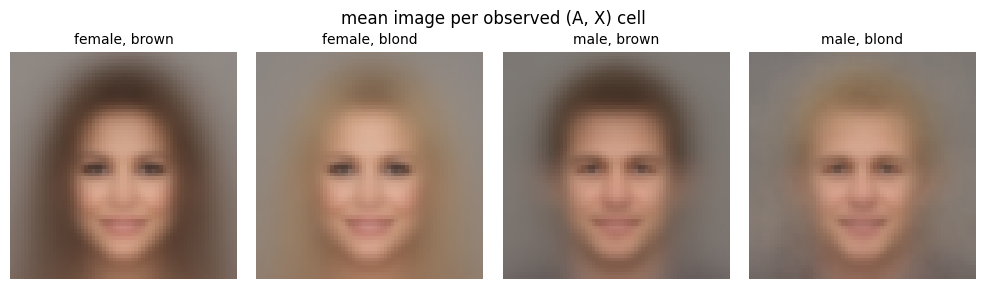

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(10, 2.9))
for ax, ((a, x), label) in zip(axes, cells.items()):
    idx = torch.where((A == a) & (X == x))[0]
    mean_face = to_image_range(Y[idx].mean(0))
    ax.imshow(mean_face.permute(1, 2, 0).cpu().numpy())
    ax.set_title(label, fontsize=10)
    ax.axis("off")
fig.suptitle("mean image per observed (A, X) cell", fontsize=12)
fig.tight_layout()
plt.show()

## 3. Overlap

With a binary confounder the oracle propensity takes two values per arm, so the
deterministic-intervention weights $w^{(a)} = \mathbf 1\{A = a\}/P(A = a \mid X)$ form a two-point
distribution and the effective sample size is governed entirely by the cell imbalance. The minority
cell of each arm (blond males; blond females are the majority of arm 0) carries the large
weights.

In [5]:
propensity_1 = torch.where(X == 1, torch.tensor(0.1), torch.tensor(0.6))
print(f"{'arm':>4s} {'size':>7s} {'ESS':>8s} {'ESS / size':>12s} {'weights (brown, blond)':>24s}")
for a in (0, 1):
    e_a = propensity_1 if a == 1 else 1.0 - propensity_1
    on_arm = (1.0 / e_a[A == a]).numpy()
    ess = effective_sample_size(on_arm)
    w_brown = 1.0 / (0.6 if a == 1 else 0.4)
    w_blond = 1.0 / (0.1 if a == 1 else 0.9)
    print(f"{a:>4d} {int((A == a).sum()):7d} {ess:8.1f} {ess / (A == a).sum().item():12.3f} "
      f"{w_brown:13.2f}, {w_blond:6.2f}")

 arm    size      ESS   ESS / size   weights (brown, blond)
   0   11000   9600.0        0.873          2.50,   1.11
   1    9000   4800.0        0.533          1.67,  10.00


## 4. Feasibility of the Design

The observed and reference samples are disjoint within cells, so each cell of the cleaned pool
bounds the achievable $n_{\mathrm{obs}}$. The blond-male cell binds:

| cell $(A, X)$ | pool | fraction of $n_{\mathrm{obs}}$ | reference need | max $n_{\mathrm{obs}}$ |
|---|---|---|---|---|
| female, brown | 24,360 | 0.28 | 1,400 | 81,900 |
| male, brown | 11,123 | 0.42 | 1,400 | 23,150 |
| female, blond | 24,288 | 0.27 | 600 | 87,733 |
| **male, blond** | **1,266** | **0.03** | **600** | **22,200** |

With $n_{\mathrm{ref}} = 2{,}000$ per arm the maximum feasible observed sample is
$n_{\mathrm{obs}} = 22{,}200$, which is why the design uses $n \approx 20{,}000$ ("limited by the
smallest cell").

## Summary

- The construction is deterministic in its cell counts and reproduces the prescribed probabilities
  **exactly** ($P(X{=}1) = 0.3000$, $P(A{=}1|X{=}0) = 0.6000$, $P(A{=}1|X{=}1) = 0.1000$); the
  implementation is verified file-set-identical to the reference code on the cleaned 61,037-image
  pool.
- Overlap is asymmetric across arms: arm 1 concentrates weight 10 on its 600 blond males
  (on-arm ESS $\approx 53\%$ of the arm), while arm 0's weights are mild (ESS $\approx 87\%$).
- The blond-male cell (1,266 images) caps the design at $n_{\mathrm{obs}} = 22{,}200$ given the
  balanced references — the paper's $n \approx 20{,}000$ sits just under this cap.
- The interventional references share the balanced colour law $P(X{=}1) = 0.3$ but differ in the
  facial-attribute distribution of the arm, mirroring the ColorMNIST structure at photographic
  complexity.